# Perch2_01: Perch 2.0 embeddings + linear probe, compared with EfficientNet

Mohammed's first experiment: Perch 2.0 embeddings → PCA/UMAP → simple classifier → accuracy, precision, recall, F1
→ compare with EfficientNet → preliminary HDBSCAN clustering.

* **Embedding:** frozen Perch 2.0, `first` = first 5 s window (comparable with EfficientNet's first 4.65 s),
  `mean` = mean over up to 12 windows (the Perch 2.0 paper's protocol).
* **Classifier:** standardisation (train statistics) + logistic regression with balanced class weights;
  C chosen on validation macro-F1, test evaluated once.
* Same two splits as EfficientNet: **main** (44 species, clip-level) and **grouped** (34 species, unseen recordings).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.Perch.probe import linear_probe, few_shot, EMB_FILE
OUT = config.EVAL_DIR; FIG = config.PROJECT_ROOT / "outputs" / "perch"; FIG.mkdir(parents=True, exist_ok=True)

## 1. Linear probe on both splits

In [2]:
results, grids = [], {}
for split in ["main", "grouped"]:
    for kind in ["first", "mean"]:
        print(f"--- {split} / {kind}")
        r, g = linear_probe(split, kind)
        results.append(r); grids[(split, kind)] = g
probe = pd.DataFrame(results)
probe.to_csv(OUT / "perch_linear_probe.csv", index=False)
probe[["run", "split", "embedding", "best_C", "val_f1_macro", "accuracy", "precision_macro", "recall_macro",
       "f1_macro", "f1_weighted", "roc_auc_ovr_macro"]].round(3)

--- main / first


C=0.001  val acc 0.899 macro-F1 0.870


C=0.01   val acc 0.939 macro-F1 0.917


C=0.1    val acc 0.951 macro-F1 0.933


C=1.0    val acc 0.940 macro-F1 0.916


C=10.0   val acc 0.938 macro-F1 0.916


... (15 outputs left out)

C=0.1    val acc 0.484 macro-F1 0.376


C=1.0    val acc 0.477 macro-F1 0.398


C=10.0   val acc 0.475 macro-F1 0.394


,run,split,embedding,best_C,val_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro
0,Perch2_LR_first_main,main,first,0.1,0.933,0.941,0.941,0.915,0.924,0.941,0.999
1,Perch2_LR_mean_main,main,mean,0.1,0.926,0.943,0.937,0.918,0.924,0.943,0.999
2,Perch2_LR_first_grouped,grouped,first,10.0,0.397,0.722,0.601,0.544,0.543,0.716,0.936
3,Perch2_LR_mean_grouped,grouped,mean,1.0,0.398,0.724,0.605,0.574,0.568,0.714,0.947


## 2. Comparison with EfficientNet (test set)

EfficientNet grouped numbers are means over 3 seeds where available (`experiments.csv`).

In [3]:
summ = pd.read_csv(OUT / "summary_metrics.csv")
rows = [{"model": "EfficientNet_01 (2025 recipe)", "split": "main", "accuracy": summ.set_index("run").loc["EfficientNet_01", "accuracy"],
         "f1_macro": summ.set_index("run").loc["EfficientNet_01", "f1_macro"]}]
exp_path = OUT / "experiments.csv"
if exp_path.exists():
    exp = pd.read_csv(exp_path)
    for run, g in exp.groupby("run"):
        rows.append({"model": f"{run} (3 seeds)", "split": "grouped", "accuracy": g.test_acc.mean(), "f1_macro": g.test_f1_macro.mean(),
                     "f1_std": g.test_f1_macro.std()})
for _, r in probe.iterrows():
    rows.append({"model": f"Perch 2.0 + LR ({r.embedding})", "split": r.split, "accuracy": r.accuracy, "f1_macro": r.f1_macro})
comp = pd.DataFrame(rows).sort_values(["split", "f1_macro"], ascending=[True, False])
comp.to_csv(OUT / "perch_vs_efficientnet.csv", index=False)
comp.round(3)

,model,split,accuracy,f1_macro,f1_std
9,Perch 2.0 + LR (mean),grouped,0.724,0.568,NaN
8,Perch 2.0 + LR (first),grouped,0.722,0.543,NaN
4,EfficientNet_05 (3 seeds),grouped,0.658,0.484,0.017
5,EfficientNet_06 (3 seeds),grouped,0.668,0.451,0.046
1,EfficientNet_02b (3 seeds),grouped,0.626,0.447,0.039
2,EfficientNet_03 (3 seeds),grouped,0.577,0.423,0.037
3,EfficientNet_04 (3 seeds),grouped,0.400,0.259,0.016
0,EfficientNet_01 (2025 recipe),main,0.971,0.944,NaN
6,Perch 2.0 + LR (first),main,0.941,0.924,NaN
7,Perch 2.0 + LR (mean),main,0.943,0.924,NaN


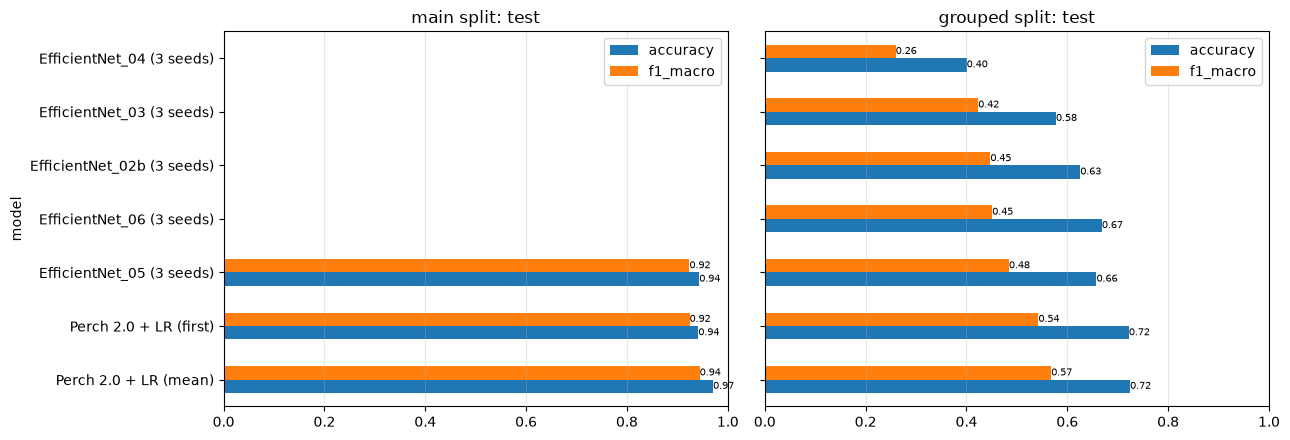

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, split in zip(axes, ["main", "grouped"]):
    d = comp[comp.split == split].set_index("model")[["accuracy", "f1_macro"]]
    d.plot.barh(ax=ax); ax.set(xlim=(0, 1), title=f"{split} split: test"); ax.grid(axis="x", alpha=.3)
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "perch_vs_efficientnet.png", dpi=150)

## 3. Per-class F1 on unseen recordings: Perch vs EfficientNet

species better with Perch: 20 of 34


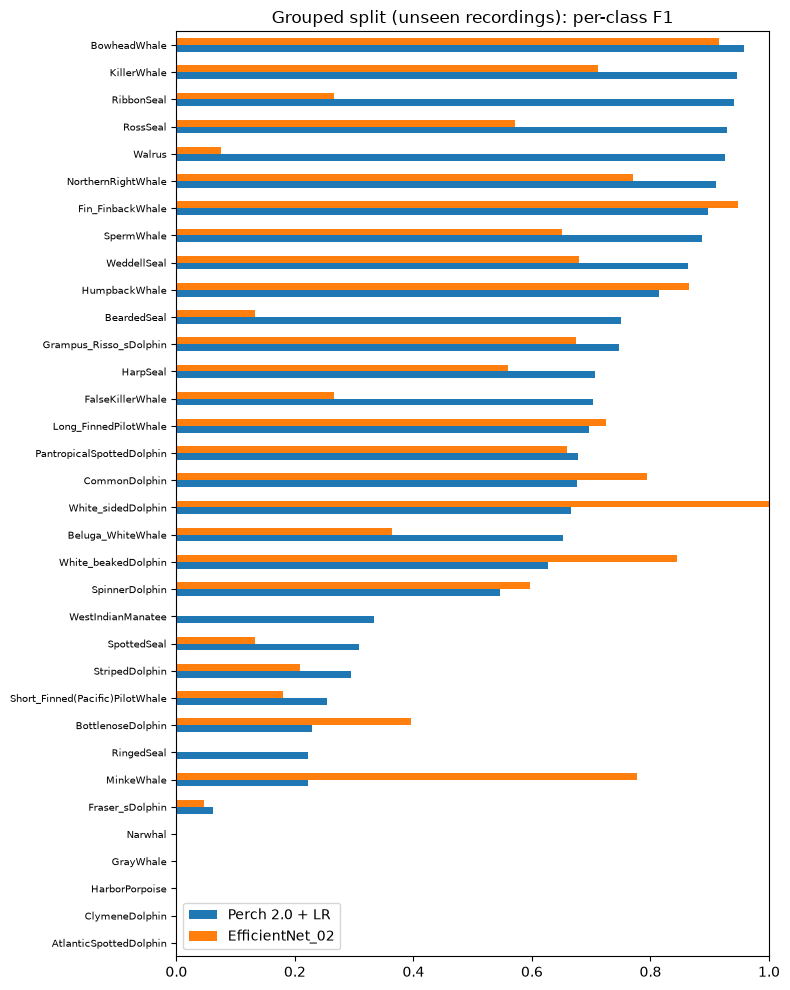

In [5]:
drop = ["accuracy", "macro avg", "weighted avg"]
p = pd.read_csv(OUT / "classification_report_Perch2_LR_first_grouped.csv", index_col=0).drop(index=drop)["f1-score"]
e = pd.read_csv(OUT / "classification_report_EfficientNet_02.csv", index_col=0).drop(index=drop)["f1-score"]
pc = pd.DataFrame({"Perch 2.0 + LR": p, "EfficientNet_02": e}).sort_values("Perch 2.0 + LR")
ax = pc.plot.barh(figsize=(8, 10)); ax.set(xlim=(0, 1), title="Grouped split (unseen recordings): per-class F1")
ax.tick_params(axis="y", labelsize=7); plt.tight_layout(); plt.savefig(FIG / "per_class_f1_perch_vs_effnet_grouped.png", dpi=150)
print("species better with Perch:", int((pc.iloc[:, 0] > pc.iloc[:, 1]).sum()), "of", len(pc))

## 4. Few-shot (as in the Perch 2.0 paper): k clips per species, 5 random draws

f1_macro        accuracy        roc_auc       
               mean    std     mean    std    mean    std
split   k                                                
grouped 4     0.337  0.048    0.461  0.081   0.897  0.025
        8     0.392  0.030    0.532  0.026   0.924  0.007
        16    0.454  0.030    0.588  0.043   0.928  0.009
        32    0.506  0.025    0.653  0.016   0.939  0.010
main    4     0.471  0.019    0.552  0.039   0.956  0.005
        8     0.591  0.023    0.653  0.028   0.976  0.002
        16    0.701  0.014    0.753  0.006   0.988  0.001
        32    0.777  0.008    0.809  0.012   0.993  0.001

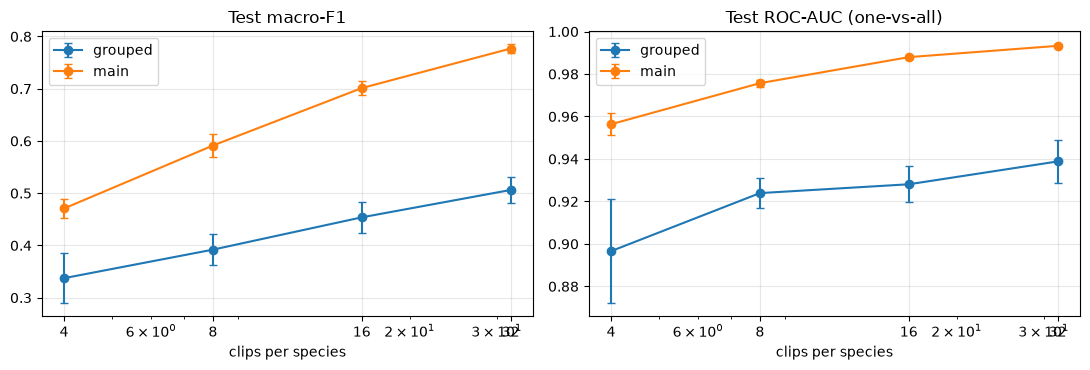

In [6]:
fs = pd.concat([few_shot("grouped"), few_shot("main")])
fs.to_csv(OUT / "perch_few_shot.csv", index=False)
agg = fs.groupby(["split", "k"])[["f1_macro", "accuracy", "roc_auc"]].agg(["mean", "std"]).round(3)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for split, g in fs.groupby("split"):
    m = g.groupby("k").mean(numeric_only=True); s = g.groupby("k").std(numeric_only=True)
    ax[0].errorbar(m.index, m.f1_macro, s.f1_macro, marker="o", capsize=3, label=split)
    ax[1].errorbar(m.index, m.roc_auc, s.roc_auc, marker="o", capsize=3, label=split)
ax[0].set(xscale="log", xticks=[4, 8, 16, 32], xticklabels=[4, 8, 16, 32], xlabel="clips per species", title="Test macro-F1")
ax[1].set(xscale="log", xticks=[4, 8, 16, 32], xticklabels=[4, 8, 16, 32], xlabel="clips per species", title="Test ROC-AUC (one-vs-all)")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "few_shot.png", dpi=150)
agg

## 5. What does the embedding capture? PCA / UMAP

Coloured by species (12 largest) and by original sample rate: does the representation group *species* or *recording equipment*?

variance explained by 2 / 10 / 50 PCs: 0.114 0.291 0.559


C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


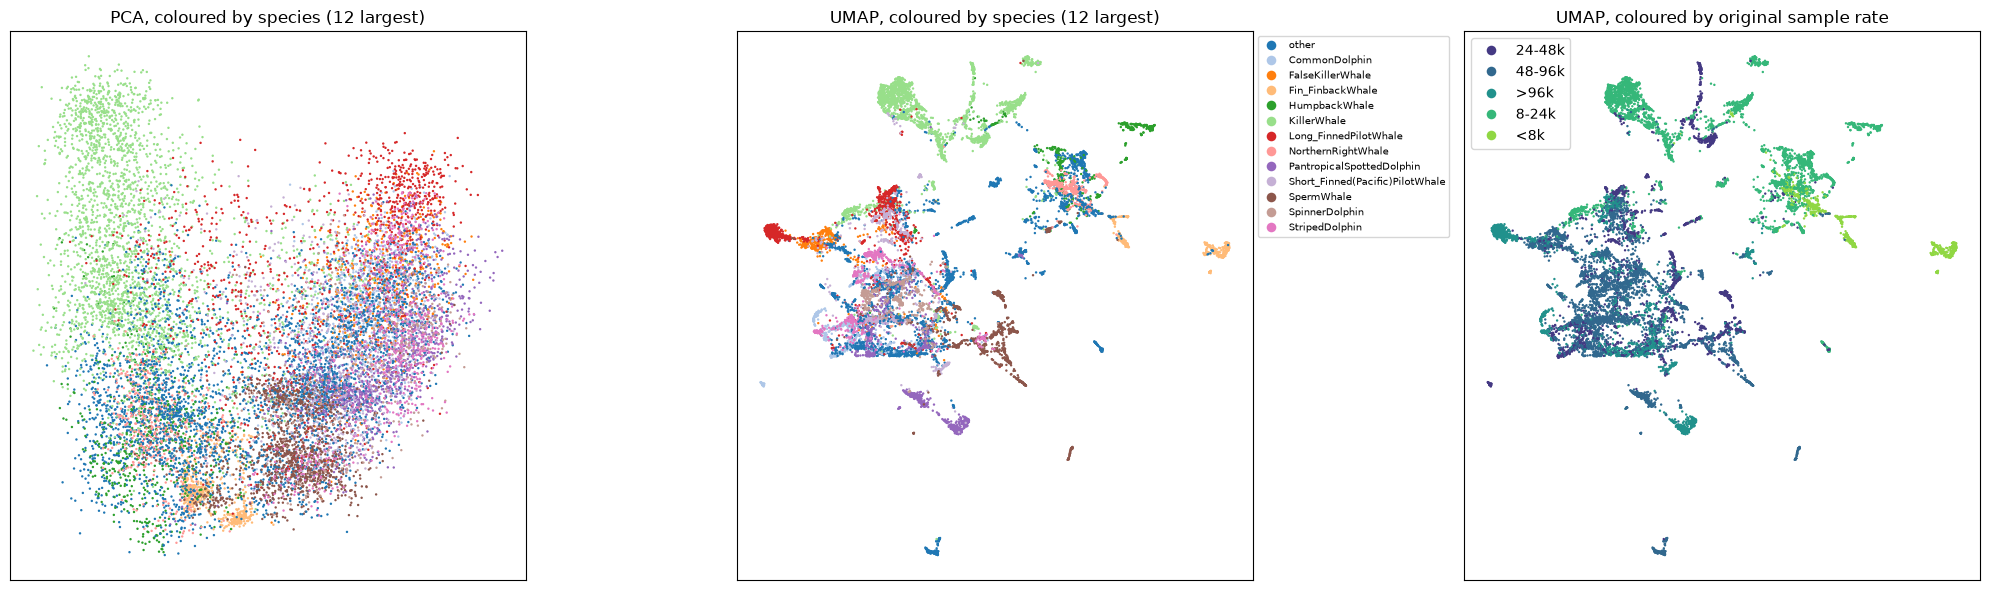

In [7]:
from src import config
import umap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
z = np.load(EMB_FILE, allow_pickle=True)
ann = pd.read_csv(config.ANNOT_DIR / "audio_annotations.csv").set_index("filename").loc[z["filename"]]
X = StandardScaler().fit_transform(z["emb_first"])
pca = PCA(50, random_state=0).fit(X); P = pca.transform(X)
print("variance explained by 2 / 10 / 50 PCs:", pca.explained_variance_ratio_[:2].sum().round(3),
      pca.explained_variance_ratio_[:10].sum().round(3), pca.explained_variance_ratio_.sum().round(3))
U = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=0).fit_transform(P)
top = ann.category.value_counts().index[:12]
lab = np.where(ann.category.isin(top), ann.category, "other")
srb = pd.cut(ann.sample_rate, [0, 8000, 24000, 48000, 96000, 1e6], labels=["<8k", "8-24k", "24-48k", "48-96k", ">96k"])
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (emb2, name) in zip(axes[:2], [(P[:, :2], "PCA"), (U, "UMAP")]):
    sns.scatterplot(x=emb2[:, 0], y=emb2[:, 1], hue=lab, s=3, linewidth=0, ax=ax, palette="tab20", legend=(name == "UMAP"))
    ax.set(title=f"{name}, coloured by species (12 largest)", xticks=[], yticks=[])
axes[1].legend(markerscale=4, fontsize=7, bbox_to_anchor=(1, 1))
sns.scatterplot(x=U[:, 0], y=U[:, 1], hue=srb.astype(str), s=3, linewidth=0, ax=axes[2], palette="viridis")
axes[2].set(title="UMAP, coloured by original sample rate", xticks=[], yticks=[]); axes[2].legend(markerscale=4)
plt.tight_layout(); plt.savefig(FIG / "pca_umap.png", dpi=150)

## 6. Preliminary unsupervised clustering (HDBSCAN, no labels)

Like the Posidonia pipeline (PCA → HDBSCAN). Agreement with labels is measured with ARI / NMI against
**species** and against **recording**: if clusters match recordings better than species, the embedding groups
recording conditions more than calls.

In [8]:
from sklearn.cluster import HDBSCAN
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
res = []
for name, F in [("PCA-50", P), ("UMAP-10", umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0, random_state=0).fit_transform(P))]:
    for mcs in [15, 30, 60]:
        cl = HDBSCAN(min_cluster_size=mcs, min_samples=5).fit_predict(F)
        m = cl >= 0
        res.append({"space": name, "min_cluster_size": mcs, "clusters": cl.max() + 1, "noise": round(1 - m.mean(), 3),
                    "ARI_species": adjusted_rand_score(ann.category[m], cl[m]), "NMI_species": normalized_mutual_info_score(ann.category[m], cl[m]),
                    "ARI_recording": adjusted_rand_score(ann.recording[m], cl[m]), "NMI_recording": normalized_mutual_info_score(ann.recording[m], cl[m])})
        if name == "UMAP-10" and mcs == 30: best_cl = cl
hdb = pd.DataFrame(res).round(3); hdb.to_csv(OUT / "perch_hdbscan.csv", index=False); hdb

C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\WORK&UNI\Master\Önlab\onlab-cetacean\.venv-perch\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,space,min_cluster_size,clusters,noise,ARI_species,NMI_species,ARI_recording,NMI_recording
0,PCA-50,15,78,0.611,0.464,0.783,0.448,0.824
1,PCA-50,30,43,0.629,0.500,0.792,0.375,0.790
2,PCA-50,60,30,0.641,0.507,0.783,0.363,0.767
3,UMAP-10,15,225,0.220,0.171,0.657,0.470,0.793
4,UMAP-10,30,123,0.186,0.253,0.667,0.388,0.763
5,UMAP-10,60,69,0.164,0.293,0.668,0.369,0.738


In [9]:
# purity: for each cluster, share of its clips that belong to its most common species
m = best_cl >= 0
pur = pd.crosstab(best_cl[m], ann.category[m])
top_sp = pur.idxmax(axis=1); purity = (pur.max(axis=1) / pur.sum(axis=1)).round(2)
summary = pd.DataFrame({"size": pur.sum(axis=1), "main_species": top_sp, "purity": purity}).sort_values("size", ascending=False)
print("clusters with purity >= 0.9:", int((summary.purity >= 0.9).sum()), "of", len(summary))
summary.head(20)

clusters with purity >= 0.9: 78 of 123


,size,main_species,purity
row_0,,,
54,759,KillerWhale,1.00
44,443,Long_FinnedPilotWhale,0.98
69,386,Long_FinnedPilotWhale,0.68
36,305,KillerWhale,0.90
0,303,Fin_FinbackWhale,0.98
13,282,PantropicalSpottedDolphin,0.98
37,258,KillerWhale,0.93
60,238,StripedDolphin,0.94
57,205,Long_FinnedPilotWhale,0.57
